# Tuần 3 – Feature Engineering & Xử lý mất cân bằng dữ liệu

**Mục tiêu:**  
- Chia dữ liệu thành **train / test** (80/20) đúng cách (`stratify` theo nhãn).  
- Áp dụng pipeline tiền xử lý (`build_preprocessor`) cho cả hai tập.  
- **CHỈ** áp dụng SMOTE lên tập **train** để tránh rò rỉ dữ liệu (Data Leakage).  
- Kiểm tra lại tỷ lệ lớp trước / sau SMOTE và xác nhận tập test giữ nguyên phân phối gốc.

> ⚠️ **Lưu ý quan trọng về Data Leakage:**  
> Nếu áp dụng SMOTE **trước** khi chia train/test → mô hình "nhìn trộm" dữ liệu test → kết quả đánh giá ảo cao bất thường.  
> Thứ tự đúng bắt buộc là: **Split → Preprocess → SMOTE (chỉ train)**.

**Người thực hiện:** Hoàng Nhật Giang (ML Engineer)  
**Ngày tạo:** 13/10/2026

---
## 1. Import thư viện & Cấu hình

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

# Import preprocessor đã được xây dựng sẵn
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from preprocessing import build_preprocessor

# SMOTE – chỉ dùng trên tập train
from imblearn.over_sampling import SMOTE

import joblib
import warnings
warnings.filterwarnings('ignore')

# Cố định random seed để kết quả tái lập được
RANDOM_STATE = 42

print('✅ Import thành công!')

✅ Import thành công!


---
## 2. Đọc dữ liệu đã làm sạch

In [10]:
df = pd.read_csv('../data/processed/stroke_clean.csv')
print(f'Kích thước bộ dữ liệu: {df.shape[0]} dòng × {df.shape[1]} cột')
df.head()

Kích thước bộ dữ liệu: 5110 dòng × 11 cột


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [11]:
# Kiểm tra nhanh missing values
print('Missing values:')
print(df.isnull().sum())
print(f'\nTổng missing: {df.isnull().sum().sum()}')

Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Tổng missing: 201


In [12]:
# Kiểm tra phân phối nhãn ban đầu
print('Phân phối nhãn (stroke) trong toàn bộ dữ liệu:')
print(df['stroke'].value_counts())
print(f'\nTỷ lệ đột quỵ: {df["stroke"].mean():.2%}')
print(f'Tỷ lệ không đột quỵ / đột quỵ: {df["stroke"].value_counts()[0]}:{df["stroke"].value_counts()[1]}'
      f' ≈ {df["stroke"].value_counts()[0] / df["stroke"].value_counts()[1]:.0f}:1')

Phân phối nhãn (stroke) trong toàn bộ dữ liệu:
stroke
0    4861
1     249
Name: count, dtype: int64

Tỷ lệ đột quỵ: 4.87%
Tỷ lệ không đột quỵ / đột quỵ: 4861:249 ≈ 20:1


---
## 3. Tách Features (X) và Label (y)

In [13]:
# 10 cột đầu vào theo Data Spec v1
feature_cols = ['gender', 'age', 'hypertension', 'heart_disease',
                'ever_married', 'work_type', 'Residence_type',
                'avg_glucose_level', 'bmi', 'smoking_status']

X = df[feature_cols].copy()
y = df['stroke'].copy()

print(f'X shape: {X.shape}')
print(f'y shape: {y.shape}')
print(f'\nCác cột đầu vào: {list(X.columns)}')

X shape: (5110, 10)
y shape: (5110,)

Các cột đầu vào: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']


---
## 4. Chia Train / Test (80/20) với Stratify

Sử dụng `stratify=y` để đảm bảo cả tập train và test giữ nguyên tỷ lệ lớp như dữ liệu gốc.  
Điều này đặc biệt quan trọng khi dữ liệu mất cân bằng nghiêm trọng (chỉ ~4.9% đột quỵ).

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y  # Giữ nguyên tỷ lệ lớp
)

print(f'Tập Train: {X_train.shape[0]} mẫu ({X_train.shape[0]/len(X):.0%})') 
print(f'Tập Test:  {X_test.shape[0]} mẫu ({X_test.shape[0]/len(X):.0%})')

Tập Train: 4088 mẫu (80%)
Tập Test:  1022 mẫu (20%)


In [16]:
# Xác nhận tỷ lệ lớp được giữ nguyên ở cả 2 tập
print('Phân phối nhãn trong tập TRAIN:')
print(y_train.value_counts())
print(f'Tỷ lệ đột quỵ: {y_train.mean():.2%}\n')

print('Phân phối nhãn trong tập TEST:')
print(y_test.value_counts())
print(f'Tỷ lệ đột quỵ: {y_test.mean():.2%}')

print(f'\n→ Tỷ lệ đột quỵ gốc: {y.mean():.2%} — cả 2 tập đều xấp xỉ tỷ lệ này ✅')

Phân phối nhãn trong tập TRAIN:
stroke
0    3889
1     199
Name: count, dtype: int64
Tỷ lệ đột quỵ: 4.87%

Phân phối nhãn trong tập TEST:
stroke
0    972
1     50
Name: count, dtype: int64
Tỷ lệ đột quỵ: 4.89%

→ Tỷ lệ đột quỵ gốc: 4.87% — cả 2 tập đều xấp xỉ tỷ lệ này ✅


---
## 5. Áp dụng Preprocessor (Pipeline tiền xử lý)

Sử dụng `build_preprocessor()` đã được xây dựng sẵn trong `preprocessing.py`.  
Pipeline bao gồm:
- **Numeric** (`age`, `avg_glucose_level`, `bmi`): `SimpleImputer(median)` → `StandardScaler`
- **Categorical** (`gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`): `SimpleImputer(most_frequent)` → `OneHotEncoder`
- **Passthrough** (`hypertension`, `heart_disease`): giữ nguyên (đã là 0/1)

> ⚠️ **Quan trọng:** Phải `fit` trên tập **train** rồi `transform` cả 2 tập.  
> Không được `fit` trên toàn bộ dữ liệu → sẽ gây Data Leakage.

In [17]:
preprocessor = build_preprocessor()

# FIT trên tập train, rồi TRANSFORM cả 2 tập
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed  = preprocessor.transform(X_test)

print(f'X_train sau tiền xử lý: {X_train_processed.shape}')
print(f'X_test  sau tiền xử lý: {X_test_processed.shape}')

X_train sau tiền xử lý: (4088, 21)
X_test  sau tiền xử lý: (1022, 21)


In [18]:
# Xem tên các cột sau OneHotEncoder
feature_names = preprocessor.get_feature_names_out()
print(f'Tổng số features sau tiền xử lý: {len(feature_names)}')
print(f'\nDanh sách features:')
for i, name in enumerate(feature_names, 1):
    print(f'  {i:2d}. {name}')

Tổng số features sau tiền xử lý: 21

Danh sách features:
   1. num__age
   2. num__avg_glucose_level
   3. num__bmi
   4. cat__gender_Female
   5. cat__gender_Male
   6. cat__gender_Other
   7. cat__ever_married_No
   8. cat__ever_married_Yes
   9. cat__work_type_Govt_job
  10. cat__work_type_Never_worked
  11. cat__work_type_Private
  12. cat__work_type_Self-employed
  13. cat__work_type_children
  14. cat__Residence_type_Rural
  15. cat__Residence_type_Urban
  16. cat__smoking_status_Unknown
  17. cat__smoking_status_formerly smoked
  18. cat__smoking_status_never smoked
  19. cat__smoking_status_smokes
  20. pass__hypertension
  21. pass__heart_disease


In [19]:
# Chuyển sang DataFrame để dễ kiểm tra
df_train_processed = pd.DataFrame(X_train_processed, columns=feature_names)
print('5 dòng đầu tiên của tập train sau tiền xử lý:')
df_train_processed.head()

5 dòng đầu tiên của tập train sau tiền xử lý:


,num__age,num__avg_glucose_level,num__bmi,cat__gender_Female,cat__gender_Male,cat__gender_Other,cat__ever_married_No,cat__ever_married_Yes,cat__work_type_Govt_job,cat__work_type_Never_worked,...,cat__work_type_Self-employed,cat__work_type_children,cat__Residence_type_Rural,cat__Residence_type_Urban,cat__smoking_status_Unknown,cat__smoking_status_formerly smoked,cat__smoking_status_never smoked,cat__smoking_status_smokes,pass__hypertension,pass__heart_disease
0,0.205661,-0.819973,0.543113,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-1.254901,0.352075,-1.015569,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1.046590,0.090662,-0.513184,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.028623,-0.903944,-0.526066,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-1.299160,-0.529834,0.349888,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0


In [20]:
# Kiểm tra: Không còn missing values sau tiền xử lý
print(f'Missing values trong tập train sau xử lý: {np.isnan(X_train_processed).sum()}')
print(f'Missing values trong tập test sau xử lý:  {np.isnan(X_test_processed).sum()}')
print('\n✅ Không còn missing values!')

Missing values trong tập train sau xử lý: 0
Missing values trong tập test sau xử lý:  0

✅ Không còn missing values!


---
## 6. Áp dụng SMOTE – Chỉ trên tập TRAIN

### ⚠️ Data Leakage – Lỗi kinh điển cần tránh

```
❌ SAI: SMOTE(toàn bộ dữ liệu) → Split train/test  
   → Dữ liệu tổng hợp (synthetic) rò rỉ vào test → kết quả ảo cao

✅ ĐÚNG: Split train/test → SMOTE(chỉ tập train)  
   → Tập test giữ nguyên phân phối thật → đánh giá trung thực
```

SMOTE (Synthetic Minority Oversampling Technique) tạo ra các mẫu nhân tạo cho lớp thiểu số (đột quỵ) bằng cách nội suy giữa các mẫu lân cận.

In [21]:
print('=== TRƯỚC KHI ÁP DỤNG SMOTE ===')
print(f'Tập train: {X_train_processed.shape[0]} mẫu')
print(f'  - Không đột quỵ (0): {(y_train == 0).sum()}')
print(f'  - Đột quỵ      (1): {(y_train == 1).sum()}')
print(f'  - Tỷ lệ: {(y_train == 0).sum()}:{(y_train == 1).sum()}'
      f' ≈ {(y_train == 0).sum() / (y_train == 1).sum():.0f}:1')

=== TRƯỚC KHI ÁP DỤNG SMOTE ===
Tập train: 4088 mẫu
  - Không đột quỵ (0): 3889
  - Đột quỵ      (1): 199
  - Tỷ lệ: 3889:199 ≈ 20:1


In [22]:
smote = SMOTE(random_state=RANDOM_STATE)

# CHỈ áp dụng trên tập train đã qua tiền xử lý
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_processed, y_train
)

print('=== SAU KHI ÁP DỤNG SMOTE (chỉ tập TRAIN) ===')
print(f'Tập train: {X_train_resampled.shape[0]} mẫu (trước: {X_train_processed.shape[0]})')
print(f'  - Không đột quỵ (0): {(y_train_resampled == 0).sum()}')
print(f'  - Đột quỵ      (1): {(y_train_resampled == 1).sum()}')
print(f'  - Tỷ lệ: 1:1 ✅')
print(f'\nSố mẫu tổng hợp được tạo thêm: {X_train_resampled.shape[0] - X_train_processed.shape[0]}')

=== SAU KHI ÁP DỤNG SMOTE (chỉ tập TRAIN) ===
Tập train: 7778 mẫu (trước: 4088)
  - Không đột quỵ (0): 3889
  - Đột quỵ      (1): 3889
  - Tỷ lệ: 1:1 ✅

Số mẫu tổng hợp được tạo thêm: 3690


In [23]:
        # XÁC NHẬN: Tập TEST không bị thay đổi
print('=== XÁC NHẬN TẬP TEST KHÔNG BỊ ẢNH HƯỞNG ===')
print(f'Tập test: {X_test_processed.shape[0]} mẫu (giữ nguyên)')
print(f'  - Không đột quỵ (0): {(y_test == 0).sum()}')
print(f'  - Đột quỵ      (1): {(y_test == 1).sum()}')
print(f'  - Tỷ lệ đột quỵ:    {y_test.mean():.2%} (≈ phân phối gốc {y.mean():.2%}) ✅')
print(f'\n→ Tập test giữ nguyên phân phối thật → đánh giá mô hình sẽ trung thực.')

=== XÁC NHẬN TẬP TEST KHÔNG BỊ ẢNH HƯỞNG ===
Tập test: 1022 mẫu (giữ nguyên)
  - Không đột quỵ (0): 972
  - Đột quỵ      (1): 50
  - Tỷ lệ đột quỵ:    4.89% (≈ phân phối gốc 4.87%) ✅

→ Tập test giữ nguyên phân phối thật → đánh giá mô hình sẽ trung thực.


---
## 7. Trực quan hóa phân phối lớp Trước / Sau SMOTE

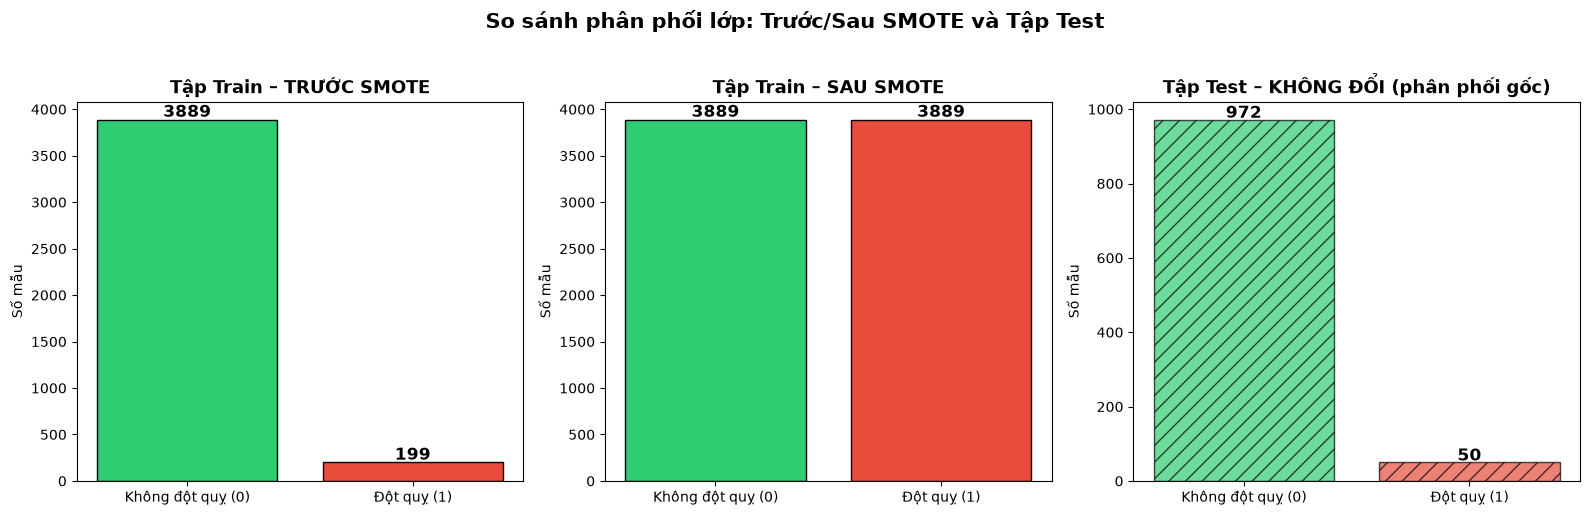


💾 Đã lưu biểu đồ → data/processed/class_distribution_smote.png


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1) Tập train TRƯỚC SMOTE
counts_before = y_train.value_counts().sort_index()
bars1 = axes[0].bar(['Không đột quỵ (0)', 'Đột quỵ (1)'],
                     counts_before.values,
                     color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title('Tập Train – TRƯỚC SMOTE', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Số mẫu')
for bar, val in zip(bars1, counts_before.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 str(val), ha='center', fontsize=12, fontweight='bold')

# 2) Tập train SAU SMOTE
counts_after = pd.Series(y_train_resampled).value_counts().sort_index()
bars2 = axes[1].bar(['Không đột quỵ (0)', 'Đột quỵ (1)'],
                     counts_after.values,
                     color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[1].set_title('Tập Train – SAU SMOTE', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Số mẫu')
for bar, val in zip(bars2, counts_after.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 str(val), ha='center', fontsize=12, fontweight='bold')

# 3) Tập test (KHÔNG THAY ĐỔI)
counts_test = y_test.value_counts().sort_index()
bars3 = axes[2].bar(['Không đột quỵ (0)', 'Đột quỵ (1)'],
                     counts_test.values,
                     color=['#2ecc71', '#e74c3c'], edgecolor='black',
                     alpha=0.7, hatch='//')
axes[2].set_title('Tập Test – KHÔNG ĐỔI (phân phối gốc)', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Số mẫu')
for bar, val in zip(bars3, counts_test.values):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(val), ha='center', fontsize=12, fontweight='bold')

plt.suptitle('So sánh phân phối lớp: Trước/Sau SMOTE và Tập Test',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/processed/class_distribution_smote.png', dpi=150, bbox_inches='tight')
plt.show()
print('\n💾 Đã lưu biểu đồ → data/processed/class_distribution_smote.png')

---
## 8. Lưu dữ liệu đã xử lý

Lưu các bộ dữ liệu đã chia và xử lý để sử dụng cho Tuần 4 (Baseline Model).

In [17]:
# Tạo thư mục nếu chưa có
os.makedirs('data/processed', exist_ok=True)

# Lưu preprocessor đã fit (Backend sẽ cần dùng lại)
joblib.dump(preprocessor, 'data/processed/preprocessor.pkl')
print('💾 Đã lưu preprocessor → data/processed/preprocessor.pkl')

# Lưu tập train ĐÃ SMOTE (dùng để train model)
np.savez('data/processed/train_resampled.npz',
         X=X_train_resampled, y=y_train_resampled)
print('💾 Đã lưu tập train (sau SMOTE) → data/processed/train_resampled.npz')

# Lưu tập train GỐC chưa SMOTE (để so sánh nếu cần)
np.savez('data/processed/train_original.npz',
         X=X_train_processed, y=y_train.values)
print('💾 Đã lưu tập train (gốc, chưa SMOTE) → data/processed/train_original.npz')

# Lưu tập test (giữ nguyên phân phối thật)
np.savez('data/processed/test.npz',
         X=X_test_processed, y=y_test.values)
print('💾 Đã lưu tập test → data/processed/test.npz')

# Lưu tên features
joblib.dump(list(feature_names), 'data/processed/feature_names.pkl')
print('💾 Đã lưu feature names → data/processed/feature_names.pkl')

💾 Đã lưu preprocessor → data/processed/preprocessor.pkl
💾 Đã lưu tập train (sau SMOTE) → data/processed/train_resampled.npz
💾 Đã lưu tập train (gốc, chưa SMOTE) → data/processed/train_original.npz
💾 Đã lưu tập test → data/processed/test.npz
💾 Đã lưu feature names → data/processed/feature_names.pkl


---
## 9. Tổng kết & Kiểm tra chéo

In [18]:
print('=' * 60)
print('         📊 TỔNG KẾT TUẦN 3 – FEATURE ENGINEERING')
print('=' * 60)

print(f'''
📁 Dữ liệu gốc:
   • {df.shape[0]} mẫu × {df.shape[1]} cột (bao gồm cột stroke)
   • Tỷ lệ đột quỵ: {y.mean():.2%} ({y.sum()} / {len(y)})
   • Missing: bmi có {df["bmi"].isnull().sum()} giá trị thiếu

✂️ Chia dữ liệu (80/20, stratify=y):
   • Train: {X_train.shape[0]} mẫu | Test: {X_test.shape[0]} mẫu

🔧 Tiền xử lý (build_preprocessor):
   • Numeric (3 cột): SimpleImputer(median) → StandardScaler
   • Categorical (5 cột): SimpleImputer(most_frequent) → OneHotEncoder
   • Passthrough (2 cột): hypertension, heart_disease
   • Tổng features sau xử lý: {X_train_processed.shape[1]} cột

⚖️ SMOTE (chỉ trên tập train):
   • Trước SMOTE: {(y_train == 0).sum()} (không) vs {(y_train == 1).sum()} (đột quỵ)
   • Sau SMOTE:   {(y_train_resampled == 0).sum()} (không) vs {(y_train_resampled == 1).sum()} (đột quỵ)
   • Mẫu tổng hợp thêm: {X_train_resampled.shape[0] - X_train_processed.shape[0]}

🧪 Tập test (KHÔNG thay đổi):
   • {X_test_processed.shape[0]} mẫu, tỷ lệ đột quỵ: {y_test.mean():.2%}
   • Giữ nguyên phân phối gốc → đánh giá mô hình trung thực ✅

💾 Files đã lưu:
   • data/processed/preprocessor.pkl
   • data/processed/train_resampled.npz (X_train + y_train sau SMOTE)
   • data/processed/train_original.npz  (X_train gốc, chưa SMOTE)
   • data/processed/test.npz            (X_test + y_test)
   • data/processed/feature_names.pkl
''')

print('=' * 60)
print('✅ Sẵn sàng cho Tuần 4: Xây dựng mô hình Baseline!')
print('=' * 60)

         📊 TỔNG KẾT TUẦN 3 – FEATURE ENGINEERING

📁 Dữ liệu gốc:
   • 5110 mẫu × 11 cột (bao gồm cột stroke)
   • Tỷ lệ đột quỵ: 4.87% (249 / 5110)
   • Missing: bmi có 201 giá trị thiếu

✂️ Chia dữ liệu (80/20, stratify=y):
   • Train: 4088 mẫu | Test: 1022 mẫu

🔧 Tiền xử lý (build_preprocessor):
   • Numeric (3 cột): SimpleImputer(median) → StandardScaler
   • Categorical (5 cột): SimpleImputer(most_frequent) → OneHotEncoder
   • Passthrough (2 cột): hypertension, heart_disease
   • Tổng features sau xử lý: 21 cột

⚖️ SMOTE (chỉ trên tập train):
   • Trước SMOTE: 3889 (không) vs 199 (đột quỵ)
   • Sau SMOTE:   3889 (không) vs 3889 (đột quỵ)
   • Mẫu tổng hợp thêm: 3690

🧪 Tập test (KHÔNG thay đổi):
   • 1022 mẫu, tỷ lệ đột quỵ: 4.89%
   • Giữ nguyên phân phối gốc → đánh giá mô hình trung thực ✅

💾 Files đã lưu:
   • data/processed/preprocessor.pkl
   • data/processed/train_resampled.npz (X_train + y_train sau SMOTE)
   • data/processed/train_original.npz  (X_train gốc, chưa SMOTE)
  

---
## 📋 Checklist kiểm tra chéo (Code Review)

Hãy nhờ **1 thành viên khác** trong nhóm kiểm tra các điểm sau trước khi merge:

| # | Kiểm tra | Đạt? |
|---|----------|------|
| 1 | `train_test_split` sử dụng `stratify=y` | ☐ |
| 2 | `preprocessor.fit_transform()` chỉ trên `X_train` | ☐ |
| 3 | `preprocessor.transform()` trên `X_test` (không fit lại) | ☐ |
| 4 | SMOTE chỉ áp dụng trên `X_train_processed` (sau split) | ☐ |
| 5 | Tập test giữ nguyên phân phối gốc (~4.9% đột quỵ) | ☐ |
| 6 | Không có missing values sau tiền xử lý | ☐ |
| 7 | `random_state=42` được cố định | ☐ |
| 8 | Preprocessor đã được lưu bằng `joblib` | ☐ |